# Referenced documents

Counts the documents each contract in `data/tous_data` refers to (privacy policies, community guidelines, payment terms, arbitration rules, ...) with `tools/references.py`, and builds two DataFrames for further analysis:

* **`refs`**: one row per *(contract, referenced document)*, with the document's category, source (own / affiliate / third party) and the cues found in the sentences that mention it (binding, incorporated, conditional, precedence, amendable).
* **`contracts`**: one row per contract, with counts of referenced documents (`n_documents` for named documents, `n_open_ended` for open-ended references such as *"additional terms"* or *"other policies"*), flag counts and counts per category (`n_cat_*`).

Both are saved to `processed_data/references/`.

The extraction is rule-based: see the module docstring in `tools/references.py` for what it finds and misses. It needs no network; measuring the *size* of referenced documents (Wayback Machine) is a separate, optional step (`analyse_contract_references(..., measure=True)`).

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from tools.references import extract_corpus_references

data_dir = Path('data/tous_data')
out_dir = Path('processed_data/references')
out_dir.mkdir(parents=True, exist_ok=True)

## Extract references from every contract

Takes about 20 seconds for the full corpus.

In [3]:
refs, contracts = extract_corpus_references(data_dir)
refs.to_csv(out_dir / 'referenced_documents.csv', index=False)
contracts.to_csv(out_dir / 'contracts_references.csv', index=False)
print(f'{len(contracts)} contracts, {len(refs)} (contract, document) rows, '
      f'{(refs.kind == "named").sum()} named and {(refs.kind == "generic").sum()} open-ended')

531 contracts, 5857 (contract, document) rows, 4344 named and 1513 open-ended


### `refs`: one row per (contract, referenced document)

| column | meaning |
|---|---|
| `contract_id`, `platform`, `folder`, `date`, `year` | contract metadata (`platform` is the filename prefix, e.g. `fb`; `folder` the directory, e.g. `facebook`) |
| `document`, `key` | surface form and normalised name (use `key` to follow a document over time) |
| `kind` | `named` (a particular document) or `generic` (open-ended: *additional terms*, *other policies*) |
| `category` | privacy, community & conduct, commerce & payments, dispute resolution, ... (`open-ended` for generic) |
| `source` | `own`, `affiliate` (same corporate group) or `third_party` |
| `n_mentions` | number of mentions in the contract |
| `binding`, `incorporated`, `conditional`, `informative`, `precedence`, `amendable` | at least one mentioning sentence contains that cue |
| `url`, `example` | URL written next to the name (rare) and the first mentioning sentence |

In [4]:
refs.head()

,contract_id,platform,folder,date,year,document,key,kind,category,source,n_mentions,binding,incorporated,conditional,informative,precedence,amendable,url,example
0,bereal_2021_08_02,bereal,bereal,2021-08-02,2021,Privacy Policy,privacy policy,named,privacy,own,3,True,True,False,False,False,False,None,Our Privacy Policy is an integral part of thes...
1,bereal_2023_04_25,bereal,bereal,2023-04-25,2023,Privacy Policy,privacy policy,named,privacy,own,2,False,False,True,True,False,False,None,To do that we created these Terms of Service (...
2,bereal_2023_04_25,bereal,bereal,2023-04-25,2023,Community Standards,community standards,named,community & conduct,own,2,True,True,False,True,False,False,None,To do that we created these Terms of Service (...
3,bereal_2023_04_25,bereal,bereal,2023-04-25,2023,help center,help center,named,help & information,own,1,False,False,False,False,False,False,None,You can reach us by postal mail at: BeReal SAS...
4,bereal_2026_03_12,bereal,bereal,2026-03-12,2026,Privacy Policy,privacy policy,named,privacy,own,5,True,False,True,True,False,False,None,To do that we created these Terms of Service (...


In [5]:
contracts.head()

,contract_id,platform,folder,date,year,contract_words,contract_sentences,n_documents,n_binding,n_incorporated,...,n_cat_developer_api,n_cat_dispute_resolution,n_cat_help_information,n_cat_intellectual_property,n_cat_law_enforcement_compliance,n_cat_open_source_licences,n_cat_other,n_cat_other_terms_conditions,n_cat_privacy,documents_per_1k_words
0,bereal_2021_08_02,bereal,bereal,2021-08-02,2021,2373,55,1,1,1,...,0,0,0,0,0,0,0,0,1,0.421408
1,bereal_2023_04_25,bereal,bereal,2023-04-25,2023,1740,77,3,1,1,...,0,0,1,0,0,0,0,0,1,1.724138
2,bereal_2026_03_12,bereal,bereal,2026-03-12,2026,2566,116,4,2,1,...,0,0,1,0,0,0,0,0,1,1.558846
3,bereal_2026_06_30,bereal,bereal,2026-06-30,2026,2313,106,3,1,0,...,0,0,1,0,0,0,0,0,2,1.297017
4,bluesky_2024_02_05,bluesky,bluesky,2024-02-05,2024,3576,191,7,3,0,...,0,4,0,1,0,0,0,0,1,1.957494


In [6]:
contracts.columns

Index(['contract_id', 'platform', 'folder', 'date', 'year', 'contract_words',
       'contract_sentences', 'n_documents', 'n_binding', 'n_incorporated',
       'n_conditional', 'n_precedence', 'n_amendable', 'n_third_party',
       'n_affiliate', 'n_mentions', 'n_open_ended', 'open_ended_precedence',
       'n_cat_advertising_branded_content', 'n_cat_ai_features',
       'n_cat_app_stores_third_party_services', 'n_cat_commerce_payments',
       'n_cat_community_conduct', 'n_cat_developer_api',
       'n_cat_dispute_resolution', 'n_cat_help_information',
       'n_cat_intellectual_property', 'n_cat_law_enforcement_compliance',
       'n_cat_open_source_licences', 'n_cat_other',
       'n_cat_other_terms_conditions', 'n_cat_privacy',
       'documents_per_1k_words'],
      dtype='object')

## Number of referenced documents over time

,n_documents,n_open_ended,n_contracts
year,,,
2017,6.000000,2.807692,26
2018,7.622222,2.866667,45
2019,8.548387,3.129032,31
2020,9.736842,2.815789,38
2021,10.200000,3.533333,30
2022,11.093750,3.593750,32
2023,11.414634,4.024390,41
2024,11.780488,3.731707,41
2025,14.500000,4.100000,30


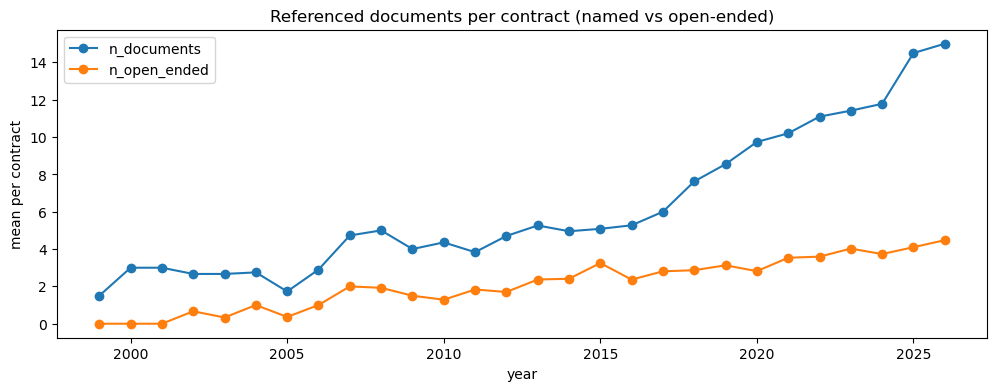

In [7]:
yearly = (contracts.groupby('year')[['n_documents', 'n_open_ended']].mean()
          .join(contracts.groupby('year').size().rename('n_contracts')))
fig, ax = plt.subplots(figsize=(12, 4))
yearly[['n_documents', 'n_open_ended']].plot(ax=ax, marker='o')
ax.set_ylabel('mean per contract')
ax.set_title('Referenced documents per contract (named vs open-ended)')
yearly.tail(10)

Text(0.5, 1.0, 'Named referenced documents per contract version')

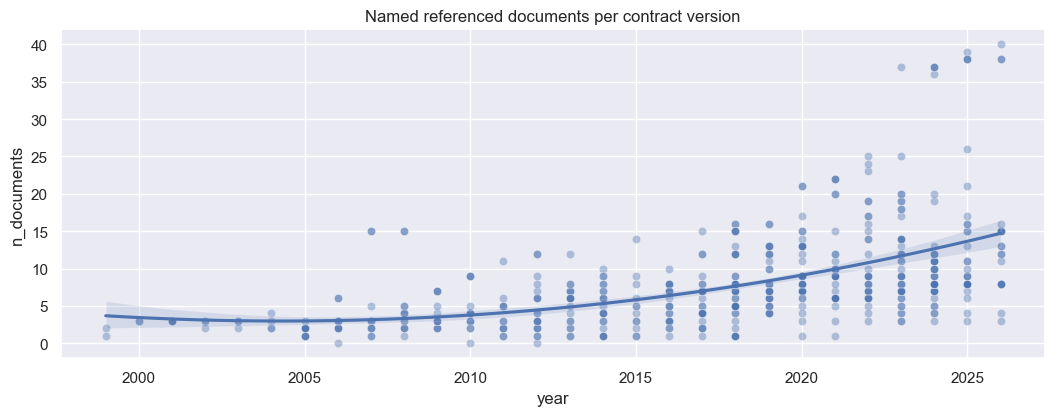

In [8]:
sns.set_theme(rc={'figure.figsize': (12.7, 4.27)})
sns.scatterplot(data=contracts, x='year', y='n_documents', alpha=.4)
sns.regplot(data=contracts, x='year', y='n_documents', order=2, scatter=False)
plt.title('Named referenced documents per contract version')

### By platform

Last version per platform and year (a platform can revise its terms several times a year). Years without a new version carry over the previous year's value, since the earlier contract stays in force.

Text(0.5, 1.0, 'Named referenced documents in force, per platform and year')

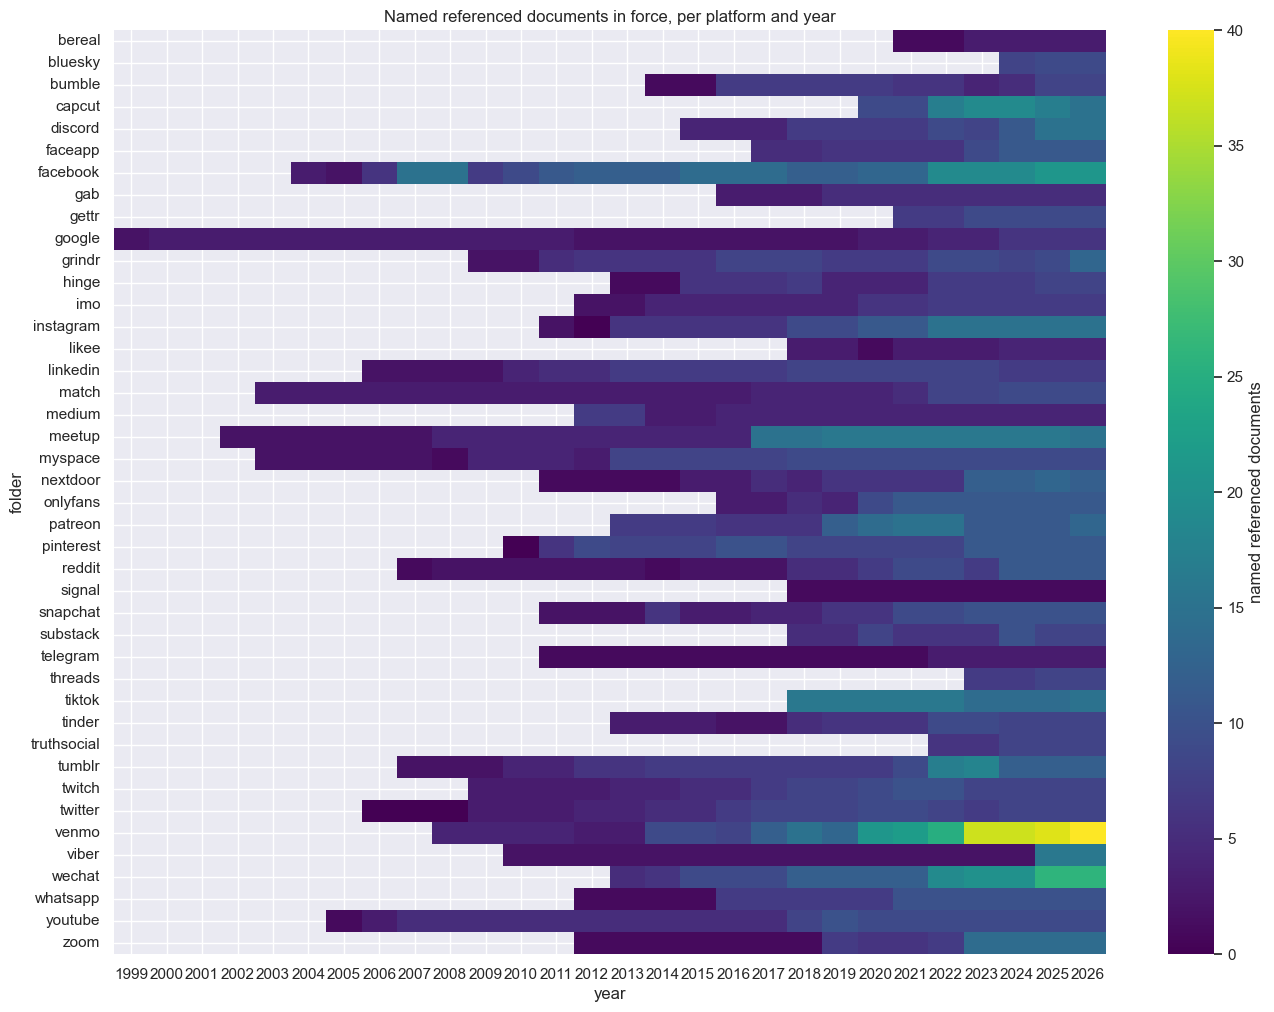

In [9]:
heat = (contracts.sort_values('date')
        .pivot_table(index='folder', columns='year', values='n_documents', aggfunc='last'))
# A contract stays in force until it is replaced: years without a new version
# carry over the value of the previous year (years before the first version stay empty).
years = range(contracts.year.min(), contracts.year.max() + 1)
heat = heat.reindex(columns=years).ffill(axis=1)
plt.figure(figsize=(16, 12))
sns.heatmap(heat, cmap='viridis', cbar_kws={'label': 'named referenced documents'})
plt.title('Named referenced documents in force, per platform and year')

In [10]:
latest = contracts.sort_values('date').groupby('folder').tail(1).set_index('folder')
latest[['contract_id', 'n_documents', 'n_open_ended', 'n_binding', 'n_incorporated',
        'n_precedence', 'n_third_party', 'documents_per_1k_words']].sort_values('n_documents', ascending=False)

,contract_id,n_documents,n_open_ended,n_binding,n_incorporated,n_precedence,n_third_party,documents_per_1k_words
folder,,,,,,,,
venmo,venmo_2026_08_24,40,5,25,3,4,11,1.155802
wechat,wechat_2025_11_18,26,7,9,2,2,6,2.459792
facebook,fb_2025_01_01,21,4,14,0,0,0,3.931848
viber,viber_2026_04_23,16,5,11,2,4,3,1.355702
tiktok,tiktok_2026_07_15,15,6,9,0,0,1,2.211737
meetup,meetup_2026_01_01,15,5,7,0,1,4,2.068395
instagram,instagram_2025_01_01,15,4,5,2,0,1,3.567182
discord,discord_2025_09_29,15,5,8,2,0,6,1.527339
capcut,capcut_2026_04_15,15,6,9,3,0,7,1.201153


## What kind of documents?

In [11]:
named = refs[refs.kind == 'named']
named.category.value_counts()

category
commerce & payments                  863
privacy                              823
community & conduct                  673
dispute resolution                   471
intellectual property                381
other terms & conditions             236
help & information                   181
app stores & third-party services    170
developer & api                      149
advertising & branded content        143
open source & licences                96
other                                 85
law enforcement & compliance          65
ai features                            8
Name: count, dtype: int64

Text(0.5, 1.0, 'Referenced documents by category')

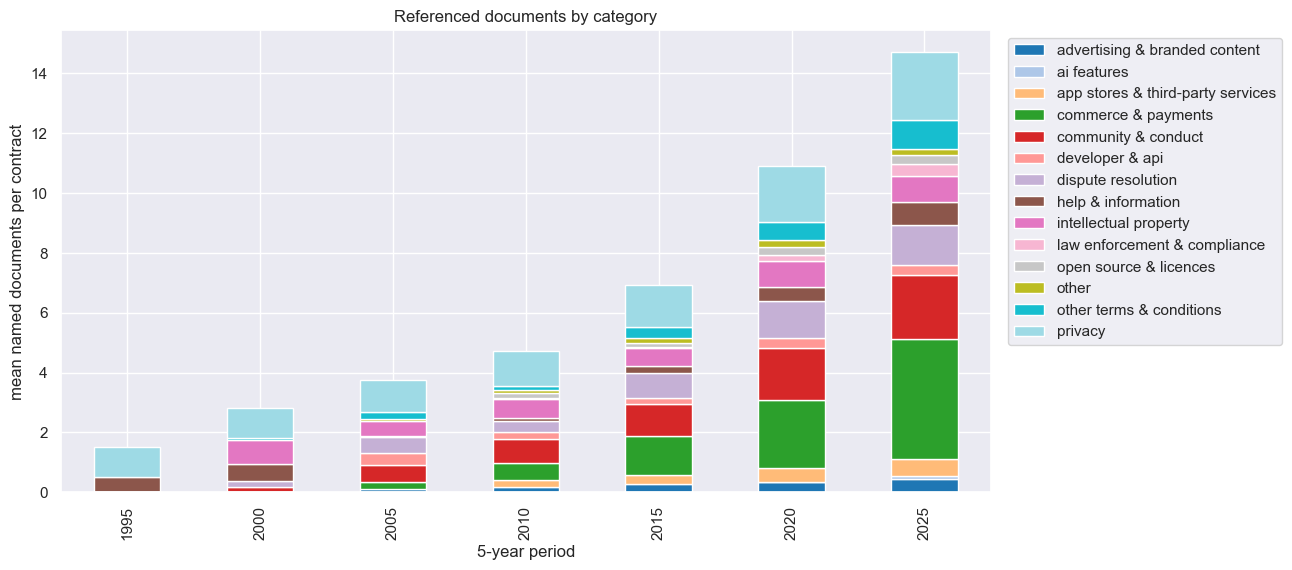

In [12]:
period = (named.year // 5) * 5
per_contract = contracts.groupby((contracts.year // 5) * 5).size()
cat_time = named.groupby([period, 'category']).size().unstack(fill_value=0).div(per_contract, axis=0)
cat_time.plot(kind='bar', stacked=True, figsize=(12, 6), colormap='tab20')
plt.ylabel('mean named documents per contract')
plt.xlabel('5-year period')
plt.legend(bbox_to_anchor=(1.01, 1), loc='upper left')
plt.title('Referenced documents by category')

Text(0.5, 1.0, 'Own, affiliate and third-party documents')

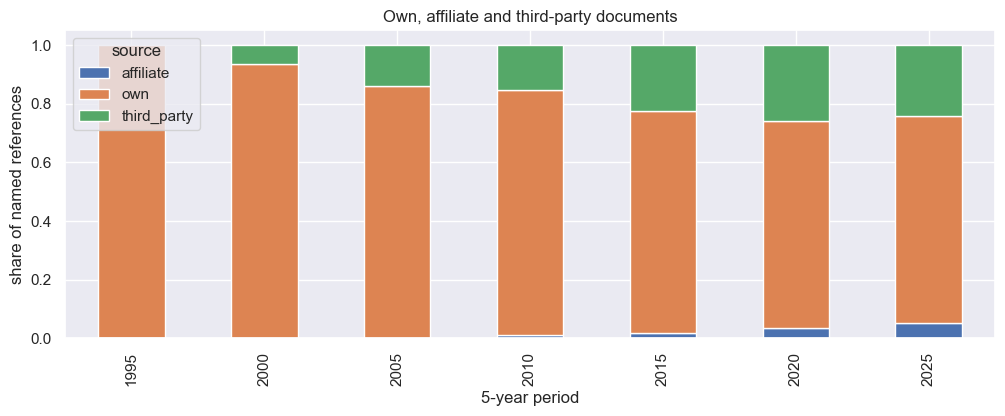

In [13]:
src_time = named.groupby([period, 'source']).size().unstack(fill_value=0)
src_time.div(src_time.sum(axis=1), axis=0).plot(kind='bar', stacked=True, figsize=(12, 4))
plt.ylabel('share of named references')
plt.xlabel('5-year period')
plt.title('Own, affiliate and third-party documents')

### Most widely referenced documents

Number of platforms whose contracts ever reference a document (by normalised `key`).

In [14]:
(named.groupby('key')
      .agg(platforms=('folder', 'nunique'), contracts=('contract_id', 'nunique'),
           category=('category', 'first'), first_year=('year', 'min'))
      .sort_values(['platforms', 'contracts'], ascending=False)
      .head(30))

,platforms,contracts,category,first_year
key,,,,
privacy policy,42,485,privacy,1999
community guidelines,20,147,community & conduct,2007
help center,19,119,help & information,2012
copyright policy,16,99,intellectual property,2003
aaa rules,14,72,dispute resolution,2006
cookie policy,12,46,privacy,2013
usage rules,11,76,community & conduct,2009
acceptable use policy,9,93,community & conduct,2003
brand guidelines,8,50,intellectual property,2010


## How references are framed

Share of contracts in which at least one named document is incorporated, made conditional, given precedence over the contract, or described as changeable; and share with an open-ended reference that is given precedence (e.g. *"if the additional terms conflict with these Terms, the additional terms will govern"*).

Text(0.5, 1.0, 'How referenced documents are framed')

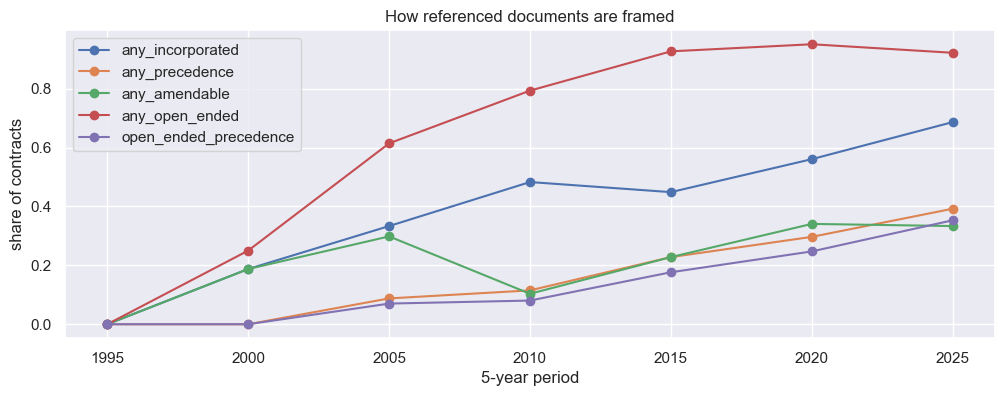

In [15]:
flags = contracts.assign(
    any_incorporated=contracts.n_incorporated > 0,
    any_precedence=contracts.n_precedence > 0,
    any_amendable=contracts.n_amendable > 0,
    any_open_ended=contracts.n_open_ended > 0,
)
flag_cols = ['any_incorporated', 'any_precedence', 'any_amendable', 'any_open_ended', 'open_ended_precedence']
flags.groupby((flags.year // 5) * 5)[flag_cols].mean().plot(marker='o', figsize=(12, 4))
plt.ylabel('share of contracts')
plt.xlabel('5-year period')
plt.title('How referenced documents are framed')

## Accretion: documents added and dropped between versions

For each pair of consecutive versions of a platform's contract, which named documents were added and which disappeared. This shows the network of documents around a contract changing between revisions.

In [16]:
def version_changes(refs, contracts):
    docs = refs[refs.kind == 'named'].groupby('contract_id')['key'].apply(set)
    rows = []
    for folder, group in contracts.sort_values('date').groupby('folder'):
        ids = list(group.contract_id)
        for prev, curr in zip(ids[:-1], ids[1:]):
            a, b = docs.get(prev, set()), docs.get(curr, set())
            rows.append({'folder': folder, 'from': prev, 'to': curr,
                         'year': group.set_index('contract_id').loc[curr, 'year'],
                         'n_added': len(b - a), 'n_dropped': len(a - b), 'n_kept': len(a & b),
                         'added': sorted(b - a), 'dropped': sorted(a - b)})
    return pd.DataFrame(rows)

changes = version_changes(refs, contracts)
changes.to_csv(out_dir / 'version_changes.csv', index=False)
changes.sort_values('n_added', ascending=False).head(15)

,folder,from,to,year,n_added,n_dropped,n_kept,added,dropped
435,viber,viber_2010_12_26,viber_2025_03_24,2025,16,2,0,"[acceptable use policy, apple terms, business ...","[app store terms and conditions, usage rules]"
423,venmo,venmo_2023_05_04,venmo_2023_12_14,2023,13,1,24,"[american express merchant operating guide, am...",[paypal help center]
198,meetup,meetup_2010_05_23,meetup_2017_03_28,2017,12,1,3,"[api license terms, cookie policy, group polic...",[hosts policies]
309,tiktok,tiktok_2023_11_01,tiktok_2026_01_22,2026,11,10,4,"[branded content policy, buyer policy, campaig...","[amazon appstore eula, amazon appstore terms o..."
447,wechat,wechat_2021_11_01,wechat_2022_04_01,2022,10,3,9,"[agreement on software license, arbitration ru...",[hong kong international arbitration center ad...
47,facebook,fb_2006_12_13,fb_2007_05_24,2007,10,1,5,"[application user terms, code of conduct, copy...",[sites privacy policy]
486,zoom,zoom_2022_12_30,zoom_2023_03_31,2023,9,3,4,"[acceptable use guidelines, apple terms, apple...","[aaa commercial arbitration rules, aaa rules, ..."
216,nextdoor,nextdoor_2019_05_06,nextdoor_2023_09_01,2023,9,3,3,"[advertising and cookie policy, business servi...","[help center, jams rules, streamlined arbitrat..."
451,wechat,wechat_2024_02_20,wechat_2025_11_18,2025,9,3,17,"[additional country-specific terms, arbitratio...","[aaa commercial arbitration rules, consumer ar..."
389,venmo,venmo_2012_08_14,venmo_2014_01_14,2014,8,2,1,"[ach rules, apple app store terms of use, cons...","[acceptable use policy, refund policy]"


Text(0.5, 1.0, 'Referenced documents added and dropped per revision')

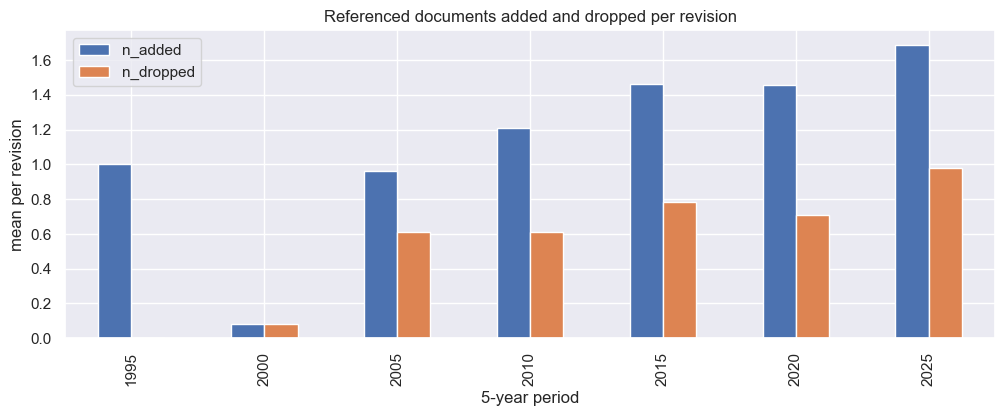

In [17]:
changes.groupby((changes.year // 5) * 5)[['n_added', 'n_dropped']].mean().plot(kind='bar', figsize=(12, 4))
plt.ylabel('mean per revision')
plt.xlabel('5-year period')
plt.title('Referenced documents added and dropped per revision')

## Following one platform

Which documents a platform's contract references, version by version.

Text(0.5, 1.0, 'Documents referenced by facebook contracts')

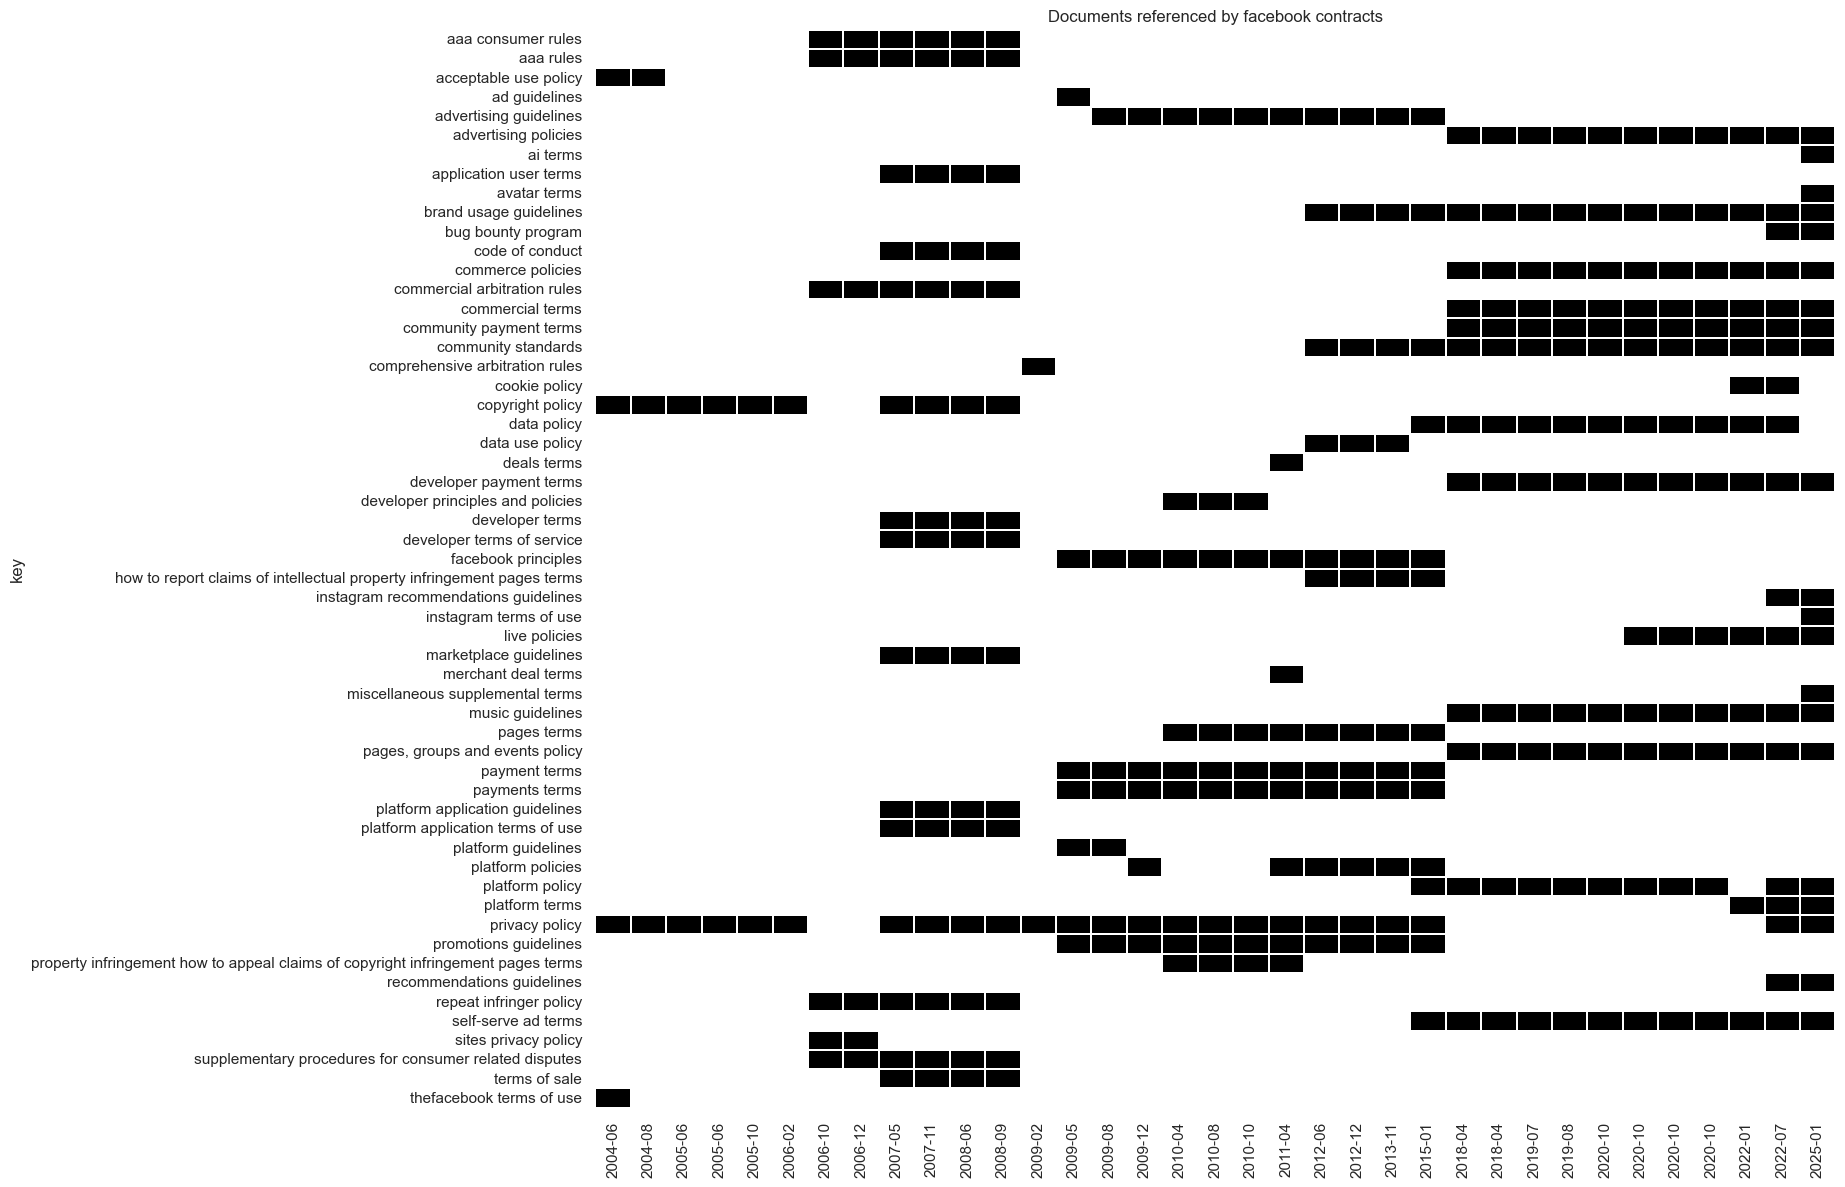

In [18]:
platform = 'facebook'
timeline = (named[named.folder == platform]
            .pivot_table(index='key', columns='date', values='n_mentions', aggfunc='sum')
            .notna())
timeline.columns = [d.strftime('%Y-%m') for d in timeline.columns]
plt.figure(figsize=(16, max(4, len(timeline) * .25)))
sns.heatmap(timeline.astype(int), cbar=False, cmap='Greys', linewidths=.2)
plt.title(f'Documents referenced by {platform} contracts')

## Caveats

* **Rule-based extraction.** A named document is found when it is written in Title Case or matches the lexicon of common document types (`KNOWN_DOCUMENTS`). Lower-case one-off references (*"the rules of the arbitration provider"*) are missed, and some section headings run together with names still slip through as false positives. Extend the rules in `tools/references.py` and rerun.
* **Normalisation.** `key` merges spelling variants and drops the platform's own brand (*Grindrs Privacy Notice* → `privacy notice`), but renamed documents (*Data Policy* → *Privacy Policy*) stay separate keys.
* **Cues are sentence-level.** `binding`, `precedence`, ... are set when any sentence mentioning the document contains the cue, so they are indicators, not legal classifications.
* **Counts are not size.** A contract that references many short pages can be lighter than one that references one long policy. Use `analyse_contract_references(..., measure=True)` on a subset to estimate size.